# 규칙이 관중을 불렀는가?
이규돈 · 데이터과학및분석소개

2010–2025년 MLB 30개 구단의 경기당 관중을 세 기준으로 비교한다. 첫 셀부터 순서대로 실행하면 표와 그래프가 생성된다. 2025년판 Teams.csv를 노트북 옆에 두거나 인터넷에 연결하면 두 번째 코드 셀이 고정 버전의 CSV를 읽는다. 그림 파일은 output/에 저장된다.

[SABR 데이터 안내](https://sabr.org/lahman-database/) · [프로젝트 설명](https://dlrbehs.github.io/mlb.html)

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson

available = {font.name for font in font_manager.fontManager.ttflist}
for family in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if family in available:
        plt.rc('font', family=family)
        break
mpl.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
os.makedirs('output', exist_ok=True)

In [2]:
import hashlib
from io import BytesIO
from urllib.request import urlopen

csv_url = 'https://raw.githubusercontent.com/corbtastik/lahman-baseball-db/b5e7327707fff91ff3bdcbe1f6892c8c5015cf1d/Teams.csv'
csv_path = Path('Teams.csv')
if csv_path.exists():
    data = csv_path.read_bytes()
else:
    with urlopen(csv_url, timeout=30) as response:
        data = response.read()
teams = pd.read_csv(BytesIO(data), encoding='utf-8-sig', encoding_errors='replace')
print('원자료 행과 열', teams.shape)
print('수록 연도', teams.yearID.min(), '–', teams.yearID.max())
print('CSV SHA-256', hashlib.sha256(data).hexdigest())

원자료 행과 열 (3614, 48)
수록 연도 1871 – 2025
CSV SHA-256 0e7afdd8b837d0edaca770a28817eec6613bd8255979c1be6e3f5827f4b88fd6


In [3]:
need = ['yearID','lgID','teamID','franchID','name','G','Ghome','W','L','park','attendance']
teams = teams.loc[teams.yearID.between(2010, 2025) & teams.lgID.isin(['AL', 'NL']), need].copy()
print('분석 표본 행과 열 (파생 전)', teams.shape)
print('결측값 수', teams.isna().sum().sum())
print('2020년 관중이 0인 구단', teams.loc[(teams.yearID == 2020) & (teams.attendance == 0), 'franchID'].nunique())
assert not teams.duplicated(['yearID', 'franchID']).any()
assert (teams.Ghome > 0).all()
assert teams.groupby('yearID').franchID.nunique().eq(30).all()
teams['att_per_game'] = teams.attendance / teams.Ghome
teams.tail()

분석 표본 행과 열 (파생 전) (480, 11)
결측값 수 0
2020년 관중이 0인 구단 30


,yearID,lgID,teamID,franchID,name,G,Ghome,W,L,park,attendance,att_per_game
3609,2025,NL,SLN,STL,St. Louis Cardinals,162,81.0,78,84,Busch Stadium III,2250007.0,27777.864198
3610,2025,AL,TBA,TBD,Tampa Bay Rays,162,81.0,77,85,Steinbrenner Field,786750.0,9712.962963
3611,2025,AL,TEX,TEX,Texas Rangers,162,81.0,81,81,Globe Life Field,2397071.0,29593.469136
3612,2025,AL,TOR,TOR,Toronto Blue Jays,162,81.0,94,68,Rogers Centre,2849935.0,35184.382716
3613,2025,NL,WAS,WSN,Washington Nationals,162,81.0,66,96,Nationals Park,1916768.0,23663.802469


In [4]:
def match_counts(start, end, key):
    by_year = teams.loc[teams.yearID.isin([start, end])].pivot(
        index=key, columns='yearID', values='att_per_game')
    return len(by_year[[start, end]].dropna())

for start, end in [(2019, 2023), (2022, 2023), (2022, 2025)]:
    print(f"{start}→{end}  teamID {match_counts(start,end,'teamID')}개, "
          f"franchID {match_counts(start,end,'franchID')}개")
print(teams.loc[(teams.franchID == 'OAK') & teams.yearID.isin([2022, 2025]),
                ['yearID','teamID','franchID']].to_string(index=False))

2019→2023  teamID 30개, franchID 30개
2022→2023  teamID 30개, franchID 30개
2022→2025  teamID 29개, franchID 30개
 yearID teamID franchID
   2022    OAK      OAK
   2025    ATH      OAK


In [5]:
summary = teams.groupby('yearID').agg(
    팀수=('teamID', 'count'),
    총관중=('attendance', 'sum'),
    총홈경기=('Ghome', 'sum'),
)
summary['경기당관중'] = round(summary['총관중'] / summary['총홈경기'], 3)
summary

,팀수,총관중,총홈경기,경기당관중
yearID,,,,
2010,30,73053807.0,2430.0,30063.295
2011,30,73425667.0,2429.0,30228.764
2012,30,74859268.0,2430.0,30806.283
2013,30,74026895.0,2431.0,30451.211
2014,30,73739622.0,2430.0,30345.523
2015,30,73719330.0,2429.0,30349.662
2016,30,73159044.0,2428.0,30131.402
2017,30,72670425.0,2430.0,29905.525
2018,30,69671272.0,2431.0,28659.511


In [6]:
g22 = summary.loc[2022, '총관중']
g23 =summary.loc[2023, '총관중']

print("MLB 공식 발표 확인")
print((g23 - g22) / g22 * 100, "%")
totals = teams.pivot(index='franchID', columns='yearID', values='attendance')
print('총관중이 증가한 구단', int((totals[2023] > totals[2022]).sum()), '/ 30')

MLB 공식 발표 확인
9.589571690653504 %
총관중이 증가한 구단 26 / 30


In [7]:
for y in [2019, 2022, 2023]:
    v = summary.loc[y, '경기당관중']
    base = summary.loc[2019, '경기당관중']
    print(y, ": 경기당관중",  v,"명","(2019 대비", round((v-base) / base * 100, 2), "%)")
change = summary.loc[2019, '경기당관중'] / summary.loc[2012, '경기당관중'] - 1
print(f'2012→2019 경기당 관중 변화율 {change:.2%}')

2019 : 경기당관중 28198.792 명 (2019 대비 0.0 %)
2022 : 경기당관중 26566.526 명 (2019 대비 -5.79 %)
2023 : 경기당관중 29114.142 명 (2019 대비 3.25 %)
2012→2019 경기당 관중 변화율 -8.46%


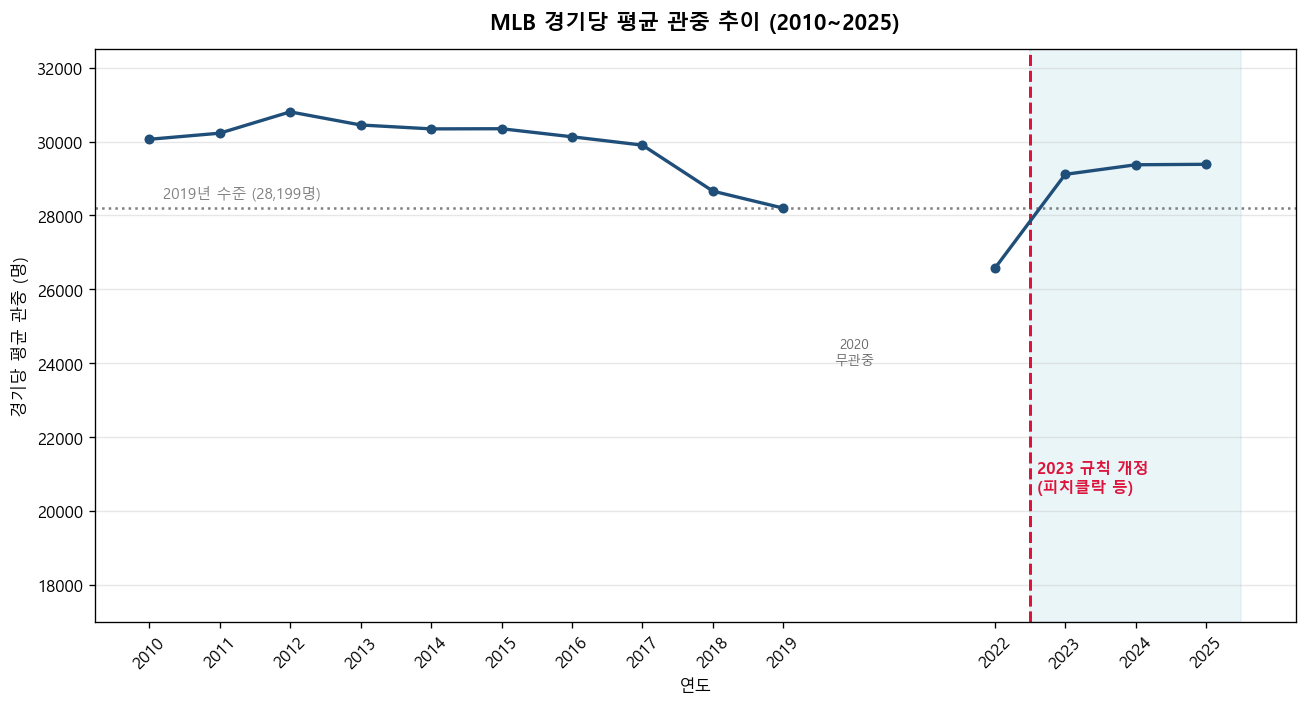

In [8]:
plot_df = summary.drop(index=[2020, 2021])
years = plot_df.index
vals = plot_df['경기당관중']

fig, ax = plt.subplots(figsize=(11, 6))

# 개입 후 구간
ax.axvspan(2022.5, 2025.5, color='lightblue', alpha=0.25, zorder=0)

# 2019년 기준 
ax.axhline(28199, color='gray', linestyle=':', linewidth=1.5, zorder=1)
ax.text(2010.2, 28199 + 300, '2019년 수준 (28,199명)',
        fontsize=9, color='gray')

ax.plot(range(2010, 2026), vals.reindex(range(2010, 2026)), marker='o', markersize=5,
        color='#1f4e79', linewidth=2, zorder=3)

# 개입
ax.axvline(2022.5, color='crimson', linestyle='--', linewidth=1.8, zorder=2)
ax.text(2022.6, 20500, '2023 규칙 개정\n(피치클락 등)',
        fontsize=9.5, color='crimson', fontweight='bold')

# 2020년 공백
ax.text(2020, 24000, '2020\n무관중', ha='center',
        fontsize=8, color='dimgray')

ax.set_xlabel('연도')
ax.set_ylabel('경기당 평균 관중 (명)')
ax.set_title('MLB 경기당 평균 관중 추이 (2010~2025)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylim(17000, 32500)
ax.set_xticks(years)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('output/fig1_league_trend.png', dpi=200, bbox_inches='tight')
plt.show()

In [9]:
# 대응 표본 t 검정
def paired_test(y0, y1, label):
    p = (teams[teams['yearID'].isin([y0, y1])]
         .pivot(index='franchID', columns='yearID', values='att_per_game')
         .dropna())
    d = p[y1] - p[y0]
 
    # 정규성 확인 
    _, w_p = stats.shapiro(d)
    # t 테스트
    t, pv = stats.ttest_rel(p[y1], p[y0])
    # 윌콕슨
    _, wil_p = stats.wilcoxon(p[y1], p[y0])
    # Cohen's d
    dz = d.mean() / d.std(ddof=1)
 
    print(f'[{label}]  n = {len(p)}')
    print(f'  평균 증가분   : {d.mean():+,.0f}명  '
          f'({d.mean() / p[y0].mean() * 100:+.1f}%)')
    print(f'  증가 구단     : {(d > 0).sum()} / {len(p)}')
    print(f'  Shapiro-Wilk  : p = {w_p:.4f}')
    print(f'  대응표본 t    : t = {t:.3f}, p = {pv:.6f}')
    print(f'  Wilcoxon      : p = {wil_p:.6f}')
    print(f"  Cohen's dz    : {dz:.3f}\n")
    return {'n': len(p), 'mean': d.mean(), 't': t, 'p': pv, 'd': dz}
 
 
# 검정
r19 = paired_test(2019, 2023, '2019 vs 2023')
r22 = paired_test(2022, 2023, '2022 vs 2023')
r25 = paired_test(2022, 2025, '2022 vs 2025')

[2019 vs 2023]  n = 30
  평균 증가분   : +918명  (+3.3%)
  증가 구단     : 15 / 30
  Shapiro-Wilk  : p = 0.2389
  대응표본 t    : t = 0.893, p = 0.379180
  Wilcoxon      : p = 0.655438
  Cohen's dz    : 0.163

[2022 vs 2023]  n = 30
  평균 증가분   : +2,551명  (+9.6%)
  증가 구단     : 26 / 30
  Shapiro-Wilk  : p = 0.7557
  대응표본 t    : t = 4.493, p = 0.000103
  Wilcoxon      : p = 0.000044
  Cohen's dz    : 0.820

[2022 vs 2025]  n = 30
  평균 증가분   : +2,824명  (+10.6%)
  증가 구단     : 22 / 30
  Shapiro-Wilk  : p = 0.3987
  대응표본 t    : t = 2.807, p = 0.008850
  Wilcoxon      : p = 0.003223
  Cohen's dz    : 0.512



In [10]:
piv = (teams[teams['yearID'].isin([2019, 2023])]
       .pivot(index='franchID', columns='yearID', values='att_per_game')
       .dropna())

piv['증가분'] = piv[2023] - piv[2019]
piv['증가율 (%)'] = piv['증가분'] / piv[2019] * 100
piv = piv.sort_values(by='증가율 (%)')

piv[piv['증가율 (%)'] <= 0]

yearID,2019,2023,증가분,증가율 (%)
franchID,,,,
OAK,20521.123457,10275.950617,-10245.172840,-49.925010
WSN,27898.530864,23034.962963,-4863.567901,-17.433061
MIN,28322.864198,24371.901235,-3950.962963,-13.949730
COL,36953.629630,32196.728395,-4756.901235,-12.872622
MIL,36090.530864,31498.111111,-4592.419753,-12.724722
ANA,37271.753086,32599.691358,-4672.061728,-12.535127
KCR,18267.395062,16136.444444,-2130.950617,-11.665323
CHC,38208.209877,34261.098765,-3947.111111,-10.330531
BOS,36106.506173,32989.259259,-3117.246914,-8.633477


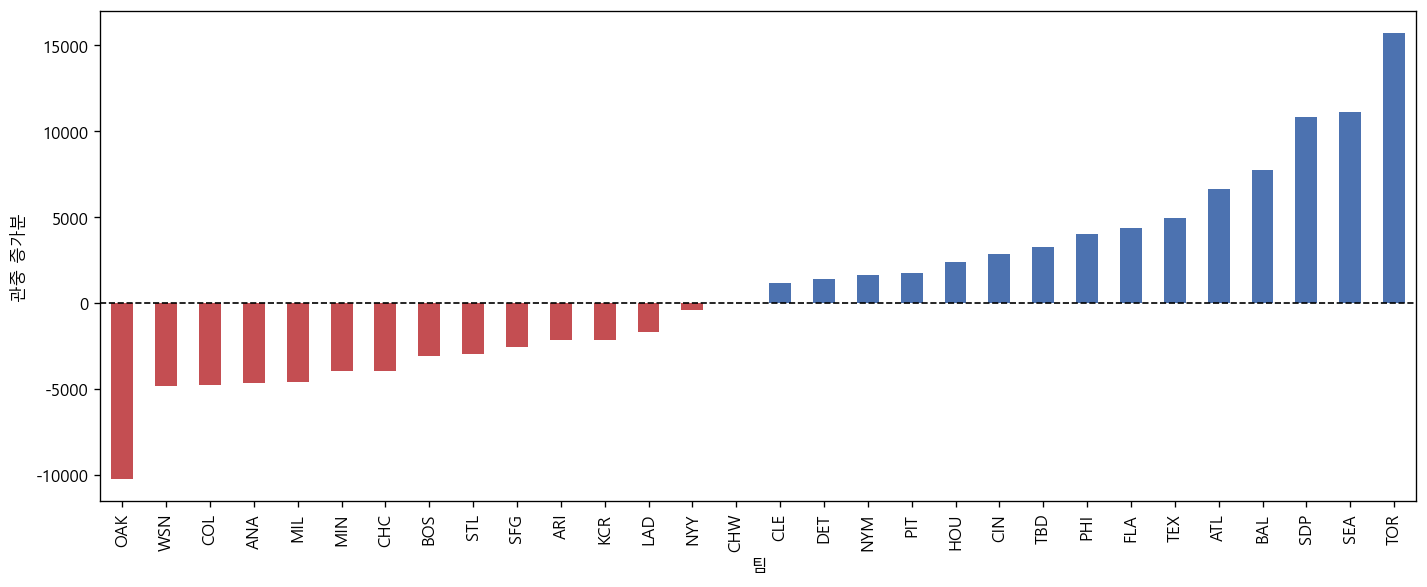

In [11]:
diff = piv['증가분'].sort_values()

# 음수=빨강, 양수=파랑
colors = ['#c44e52' if v < 0 else '#4c72b0' for v in diff]

diff.plot.bar(figsize=(12, 5), color=colors)

plt.axhline(0, linestyle='--', color='black', linewidth=1)
plt.ylabel('관중 증가분')
plt.xlabel('팀')
plt.tight_layout()
plt.show()

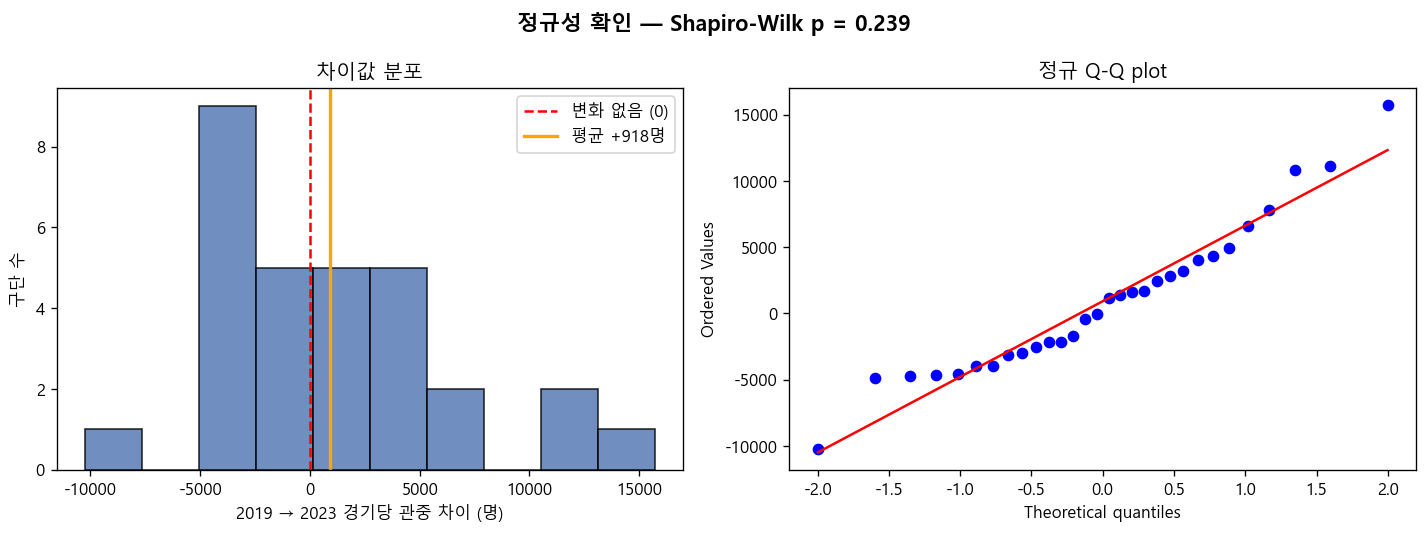

In [12]:
p = (teams[teams['yearID'].isin([2019, 2023])]
     .pivot(index='franchID', columns='yearID', values='att_per_game')
     .dropna())
d = p[2023] - p[2019]          # 음수 포함 30개

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 히스토그램
axes[0].hist(d, bins=10, color='#4c72b0', edgecolor='black', alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='변화 없음 (0)')
axes[0].axvline(d.mean(), color='orange', linewidth=2,
                label=f'평균 {d.mean():+,.0f}명')
axes[0].set_xlabel('2019 → 2023 경기당 관중 차이 (명)')
axes[0].set_ylabel('구단 수')
axes[0].set_title('차이값 분포')
axes[0].legend()

# QQ 플롯
stats.probplot(d, dist='norm', plot=axes[1])
axes[1].set_title('정규 Q-Q plot')

_, sp = stats.shapiro(d)
plt.suptitle(f'정규성 확인 — Shapiro-Wilk p = {sp:.3f}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('output/fig_normality.png', dpi=200, bbox_inches='tight')
plt.show()

In [13]:
# 각 기준연도에서 2023년까지의 구단별 변화량에 같은 규칙을 적용한다.
# 증가 구단 비율의 양측 부호검정은 변화량이 0인 구단을 분모에서 제외한다.
# 극단값 제외 후 평균 검정은 표본 선택에 민감한지 살피는 보조 분석이다.
per_game = teams.pivot(index='franchID', columns='yearID', values='att_per_game')
for start in [2019, 2022]:
    delta = (per_game[2023] - per_game[start]).dropna()
    increased = int((delta > 0).sum())
    nonzero = int((delta != 0).sum())
    sign = stats.binomtest(increased, nonzero, p=0.5, alternative='two-sided')
    q1, q3 = delta.quantile([0.25, 0.75])
    iqr = q3 - q1
    keep = delta.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    trimmed = delta[keep]
    retest = stats.ttest_1samp(trimmed, popmean=0)
    print(f'{start}→2023  증가 {increased}/{len(delta)}, 중앙값 {delta.median():+,.1f}명, 부호검정 p={sign.pvalue:.6f}')
    print(f'  1.5×IQR 경계 [{q1-1.5*iqr:,.1f}, {q3+1.5*iqr:,.1f}]명')
    print('  제외한 franchID', ', '.join(delta[~keep].index) or '없음')
    print(f'  남은 {len(trimmed)}개 중 증가 {(trimmed > 0).sum()}개, 평균 {trimmed.mean():+,.1f}명, t={retest.statistic:.3f}, p={retest.pvalue:.6f}')

2019→2023  증가 15/30, 중앙값 +584.3명, 부호검정 p=1.000000
  1.5×IQR 경계 [-13,418.7, 14,160.4]명
  제외한 franchID TOR
  남은 29개 중 증가 14개, 평균 +408.7명, t=0.442, p=0.661845
2022→2023  증가 26/30, 중앙값 +2,045.5명, 부호검정 p=0.000059
  1.5×IQR 경계 [-5,847.6, 10,755.8]명
  제외한 franchID 없음
  남은 30개 중 증가 26개, 평균 +2,551.5명, t=4.493, p=0.000103


In [14]:
league = (summary.reset_index()[['yearID', '경기당관중']]
          .rename(columns={'경기당관중': 'att_pg'}))
# 2020 무관중, 2021 제한관중 (관중 수가 팬의 선택이 아니었던 해)
league = league[~league['yearID'].isin([2020, 2021])].copy()
 
league['time'] = league['yearID'] - 2010         
league['post'] = (league['yearID'] >= 2023).astype(int)
 
print(league[['yearID', 'att_pg', 'time', 'post']].round(0).to_string(index=False))

 
model = smf.ols('att_pg ~ time + post', data=league).fit()
 
print('\n=== 회귀 결과 ===')
print(pd.DataFrame({'coef': model.params.round(1),
                    'p': model.pvalues.round(4)}).to_string())
 
b0 = model.params['Intercept']
b1 = model.params['time']
b2 = model.params['post']
ci = model.conf_int().loc['post']
 
print(f'\nR² = {model.rsquared:.3f}')
print(f'회귀식: y = {b0:,.0f} - {abs(b1):.1f}×time + {b2:,.0f}×post')
print(f'\n공통 기울기 : 연 {b1:+.1f}명  (p={model.pvalues["time"]:.4f})')
print(f'개정 전후 수준 차이 : {b2:+,.0f}명  (p={model.pvalues["post"]:.4f})')
print(f'95% 신뢰구간 : [{ci[0]:,.0f}, {ci[1]:,.0f}]')

 yearID  att_pg  time  post
   2010 30063.0     0     0
   2011 30229.0     1     0
   2012 30806.0     2     0
   2013 30451.0     3     0
   2014 30346.0     4     0
   2015 30350.0     5     0
   2016 30131.0     6     0
   2017 29906.0     7     0
   2018 28660.0     8     0
   2019 28199.0     9     0
   2022 26567.0    12     0
   2023 29114.0    13     1
   2024 29374.0    14     1
   2025 29387.0    15     1

=== 회귀 결과 ===
              coef       p
Intercept  31105.9  0.0000
time        -288.7  0.0004
post        2227.9  0.0073

R² = 0.695
회귀식: y = 31,106 - 288.7×time + 2,228×post

공통 기울기 : 연 -288.7명  (p=0.0004)
개정 전후 수준 차이 : +2,228명  (p=0.0073)
95% 신뢰구간 : [735, 3,721]


In [15]:
# 제외한 2020·2021년은 관측 행에 없다. 시차 1은 남은 자료에서 이웃한 관측값이다.
print(f'분석한 시즌 {int(model.nobs)}개, 개정 후 {league.post.sum()}개')
print(f'Durbin–Watson {durbin_watson(model.resid):.4f}')
hac = model.get_robustcov_results(cov_type='HAC', maxlags=1, kernel='bartlett',
                                 use_correction=False, use_t=False)
i = model.model.exog_names.index('post')
print(f'일반 OLS: post {model.params["post"]:+,.1f}명, p={model.pvalues["post"]:.6f}')
print(f'HAC: post {hac.params[i]:+,.1f}명, 표준오차 {hac.bse[i]:,.1f}, p={hac.pvalues[i]:.6f}')
pred = model.predict(pd.DataFrame({'time': [13, 13], 'post': [0, 1]}))
print(f'2023년 모형 적합값: post=0 {pred.iloc[0]:,.0f}명, post=1 {pred.iloc[1]:,.0f}명')

분석한 시즌 14개, 개정 후 3개
Durbin–Watson 0.6673
일반 OLS: post +2,227.9명, p=0.007266
HAC: post +2,227.9명, 표준오차 712.8, p=0.001775
2023년 모형 적합값: post=0 27,352명, post=1 29,580명


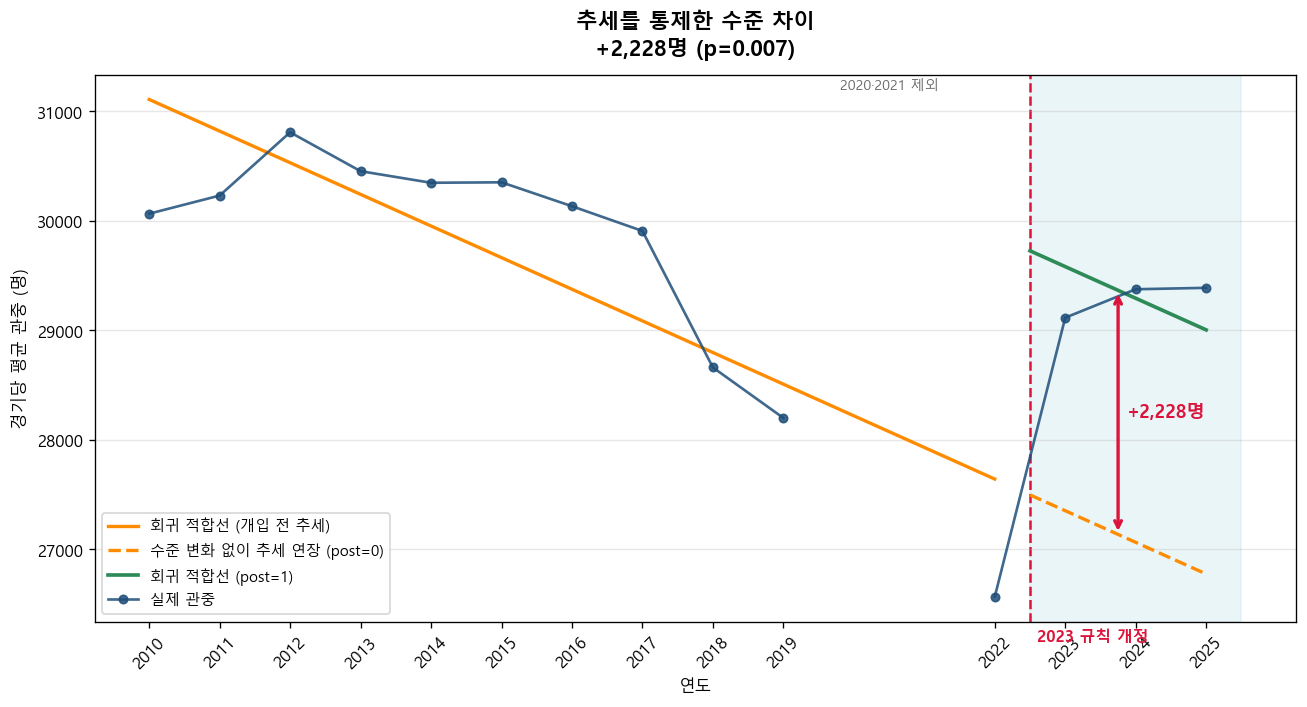

In [16]:
def yhat(year, post):
    return b0 + b1 * (year - 2010) + b2 * post
 
y_end = int(league['yearID'].max())
 
fig, ax = plt.subplots(figsize=(11, 6))
ax.axvspan(2022.5, y_end + 0.5, color='lightblue', alpha=0.25, zorder=0)
 
# 개입 전 적합선 (실선) 
ax.plot([2010, 2022], [yhat(2010, 0), yhat(2022, 0)],
        color='darkorange', linewidth=2,
        label='회귀 적합선 (개입 전 추세)', zorder=2)
 
# 개입 후: 추세 연장선(점선)과 적합선(실선)
ax.plot([2022.5, y_end], [yhat(2022.5, 0), yhat(y_end, 0)],
        color='darkorange', linewidth=2, linestyle='--',
        label='수준 변화 없이 추세 연장 (post=0)', zorder=2)
ax.plot([2022.5, y_end], [yhat(2022.5, 1), yhat(y_end, 1)],
        color='seagreen', linewidth=2.2,
        label='회귀 적합선 (post=1)', zorder=2)
 
# 실제 관측값
ax.plot(range(2010, 2026), league.set_index('yearID')['att_pg'].reindex(range(2010, 2026)), marker='o', markersize=5,
        color='#1f4e79', linewidth=1.6, alpha=0.85,
        label='실제 관중', zorder=3)
 
# 두 회귀선의 간격 = post 계수
mid = (2022.5 + y_end) / 2
ax.annotate('', xy=(mid, yhat(mid, 1)), xytext=(mid, yhat(mid, 0)),
            arrowprops=dict(arrowstyle='<->', color='crimson', lw=2))
ax.text(mid + 0.12, (yhat(mid, 1) + yhat(mid, 0)) / 2,
        f'+{b2:,.0f}명', color='crimson', fontsize=11,
        fontweight='bold', va='center')
 
ax.axvline(2022.5, color='crimson', linestyle='--', linewidth=1.5, zorder=1)
ax.text(2022.6, league['att_pg'].min() - 400, '2023 규칙 개정',
        fontsize=9.5, color='crimson', fontweight='bold')
ax.text(2020.5, league['att_pg'].max() + 400, '2020·2021 제외',
        ha='center', fontsize=8.5, color='dimgray')
 
ax.set_xlabel('연도')
ax.set_ylabel('경기당 평균 관중 (명)')
ax.set_title(f'추세를 통제한 수준 차이\n'
             f'+{b2:,.0f}명 (p={model.pvalues["post"]:.3f})',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(league['yearID'].tolist())
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='lower left', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/fig2_regression.png', dpi=200, bbox_inches='tight')
plt.show()

In [17]:
league['time'] = league['yearID'] - 2010      # 0, 1, 2, ... 15
league['post'] = (league['yearID'] >= 2023).astype(int)   # 0 또는 1
league['time_post'] = league['post'] * (league['yearID'] - 2022)

print(league[['yearID', 'att_pg', 'time', 'post', 'time_post']].to_string(index=False))
print('→ 2022년 time=12 확인 (10이면 시간 간격 왜곡)\n')

# ── 상관 확인: 왜 3변수가 안 되는지 ──────────────────
corr = league['post'].corr(league['time_post'])
print(f'post ↔ time_post 상관: {corr:.3f}')
print(f'개입 후 관측치: {league["post"].sum()}개')
print('개정 후 관측치가 적어 두 계수 추정의 불확실성이 크다.')

# ── 모형 4개 비교 ──────────────────────────────────
m0 = smf.ols('att_pg ~ post', data=league).fit()              # 추세 미통제
m1 = smf.ols('att_pg ~ time + post + time_post', data=league).fit()
m2 = smf.ols('att_pg ~ time + post', data=league).fit()       # 채택
m3 = smf.ols('att_pg ~ time + post',
             data=league[league['yearID'] != 2022]).fit()     # 민감도

compare = pd.DataFrame({
    '모형': ['⓪ post만 (추세 미통제)', '① time+post+time_post',
           '② time+post (채택)', '③ 2022 제외'],
    'post 계수': [m0.params['post'], m1.params['post'],
                m2.params['post'], m3.params['post']],
    'p값': [m0.pvalues['post'], m1.pvalues['post'],
           m2.pvalues['post'], m3.pvalues['post']],
    'R²': [m0.rsquared, m1.rsquared, m2.rsquared, m3.rsquared],
    'AIC': [m0.aic, m1.aic, m2.aic, m3.aic],
})
print(compare.round(3).to_string(index=False))
print(pd.DataFrame({'기울기 변화 허용 모형 계수': m1.params, 'p값': m1.pvalues}).round(4))
print(f'2022년 제외 시 수준 차이 {m3.params["post"]:+,.2f}명, p={m3.pvalues["post"]:.6f}')

 yearID    att_pg  time  post  time_post
   2010 30063.295     0     0          0
   2011 30228.764     1     0          0
   2012 30806.283     2     0          0
   2013 30451.211     3     0          0
   2014 30345.523     4     0          0
   2015 30349.662     5     0          0
   2016 30131.402     6     0          0
   2017 29905.525     7     0          0
   2018 28659.511     8     0          0
   2019 28198.792     9     0          0
   2022 26566.526    12     0          0
   2023 29114.142    13     1          1
   2024 29373.571    14     1          2
   2025 29386.593    15     1          3
→ 2022년 time=12 확인 (10이면 시간 간격 왜곡)

post ↔ time_post 상관: 0.908
개입 후 관측치: 3개
개정 후 관측치가 적어 두 계수 추정의 불확실성이 크다.
                   모형  post 계수    p값    R²     AIC
     ⓪ post만 (추세 미통제) -318.246 0.683 0.014 239.345
① time+post+time_post 1421.336 0.242 0.717 225.881
     ② time+post (채택) 2227.900 0.007 0.695 224.931
            ③ 2022 제외 1214.450 0.102 0.572 203.573
           기울기 변화 허용 모

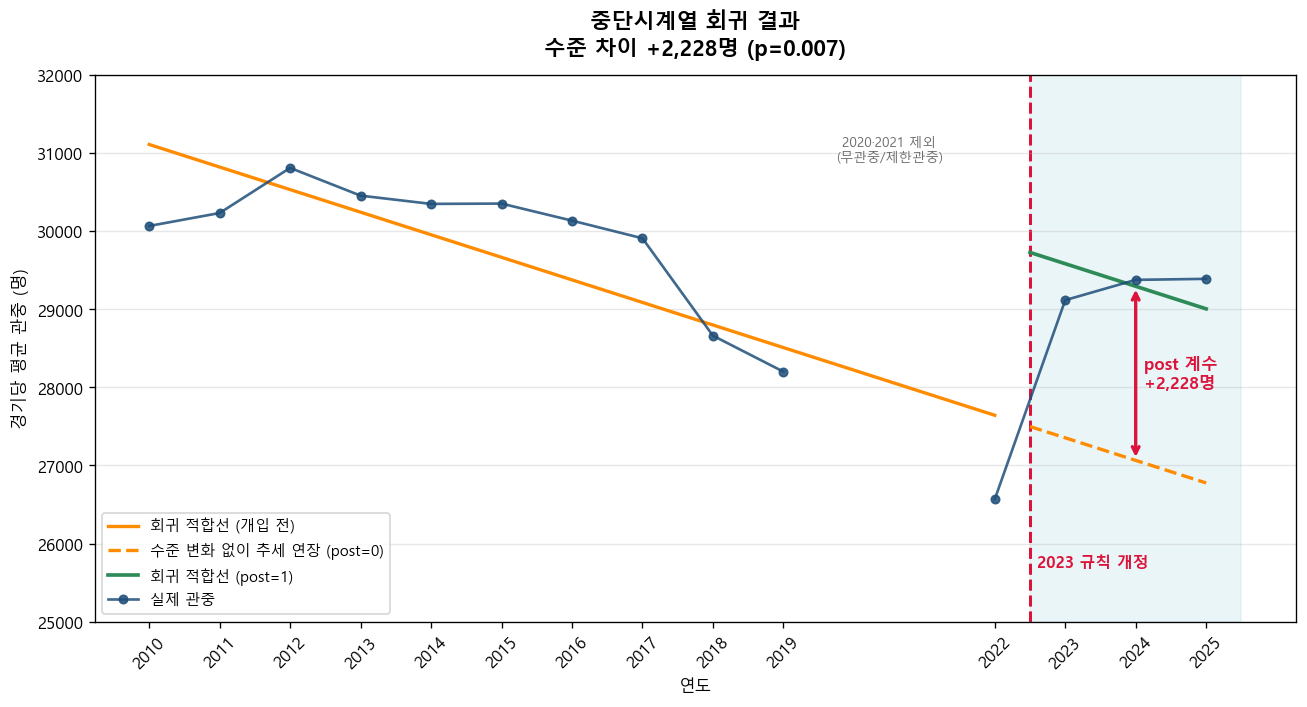

In [18]:
# ── 회귀선 두 개: post=0 과 post=1 ─────────────────
b0 = m2.params['Intercept']
b1 = m2.params['time']
b2 = m2.params['post']

def yhat(year, post):
    return b0 + b1 * (year - 2010) + b2 * post

fig, ax = plt.subplots(figsize=(11, 6))

ax.axvspan(2022.5, 2025.5, color='lightblue', alpha=0.25, zorder=0)

# ① 개입 전 구간 — 적합선 (실선)
x_pre = [2010, 2022]
ax.plot(x_pre, [yhat(x, 0) for x in x_pre],
        color='darkorange', linewidth=2, zorder=2,
        label='회귀 적합선 (개입 전)')

# ② 개입 후 구간 — 반사실 (점선, post=0)
x_post = [2022.5, 2025]
ax.plot(x_post, [yhat(x, 0) for x in x_post],
        color='darkorange', linewidth=2, linestyle='--', zorder=2,
        label='수준 변화 없이 추세 연장 (post=0)')

# ③ 개입 후 구간 — 적합선 (실선, post=1)
ax.plot(x_post, [yhat(x, 1) for x in x_post],
        color='seagreen', linewidth=2.2, zorder=2,
        label=f'회귀 적합선 (post=1)')

# ④ 실제 관측값
ax.plot(range(2010, 2026), league.set_index('yearID')['att_pg'].reindex(range(2010, 2026)), marker='o', markersize=5,
        color='#1f4e79', linewidth=1.6, alpha=0.85,
        label='실제 관중', zorder=3)

# ⑤ 두 회귀선의 간격 = post 계수
mid = 2024
ax.annotate('', xy=(mid, yhat(mid, 1)), xytext=(mid, yhat(mid, 0)),
            arrowprops=dict(arrowstyle='<->', color='crimson', lw=2))
ax.text(mid + 0.12, (yhat(mid, 1) + yhat(mid, 0)) / 2,
        f'post 계수\n+{b2:,.0f}명', color='crimson',
        fontsize=10, fontweight='bold', va='center')

ax.axvline(2022.5, color='crimson', linestyle='--', linewidth=1.8, zorder=1)
ax.text(2022.6, 25700, '2023 규칙 개정', fontsize=9.5,
        color='crimson', fontweight='bold')

ax.text(2020.5, 30900, '2020·2021 제외\n(무관중/제한관중)',
        ha='center', fontsize=8, color='dimgray')

ax.set_xlabel('연도')
ax.set_ylabel('경기당 평균 관중 (명)')
ax.set_title(f'중단시계열 회귀 결과\n'
             f'수준 차이 +{b2:,.0f}명 (p={m2.pvalues["post"]:.3f})',
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylim(25000, 32000)
ax.set_xticks(league['yearID'].tolist())
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='lower left', fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('output/fig_its.png', dpi=200, bbox_inches='tight')
plt.show()